In [48]:
# Prerequisites
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

plt.rcParams["figure.dpi"] = 300
plt.rcParams["figure.figsize"] = (12, 5)


def barplot_3D(
        mask,
        pd,
        time_values,
        alpha=1.0,
        tick_number=5,
        cmap="viridis",
    ):
    """
    Create an interactive 3D bar plot of values on a masked grid.
    Bars are colored based on their height using a colormap.
    """

    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection="3d")

    # Create grid
    x, y = np.meshgrid(pd.lons, pd.lats)
    z_base = time_values[mask].min() * 1.5
    z = np.full_like(time_values, z_base)
    dx = np.abs(pd.lons[1] - pd.lons[0])
    dy = np.abs(pd.lats[1] - pd.lats[0])
    dz = time_values[mask] - z_base

    # Normalize values to [0,1] for colormap
    norm = plt.Normalize(time_values[mask].min(), time_values[mask].max())
    colors = plt.colormaps[cmap](norm(time_values[mask]))  # updated line

    # Plot bars with color-mapped heights
    ax.bar3d(
        x[mask],
        y[mask],
        z[mask],
        dx,
        dy,
        dz,#time_values[mask],
        zsort="average",
        alpha=alpha,
        color=colors,
        edgecolor="black",
    )

    # Custom ticks
    ax.set_xticks(pd.lons[::max(1, len(pd.lons)//tick_number)])
    ax.set_yticks(pd.lats[::max(1, len(pd.lats)//tick_number)])
    ax.grid(True)

    # Axis limits and labels
    ax.set_xlim(pd.lons.min(), pd.lons.max())
    ax.set_ylim(pd.lats.min(), pd.lats.max())
    ax.set_zlim(z_base, 0.1)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_zlabel("central_time - shift_time")

    # Add a colorbar
    mappable = cm.ScalarMappable(cmap=plt.colormaps[cmap], norm=norm)
    mappable.set_array([])
    fig.colorbar(mappable, ax=ax, shrink=0.5, aspect=10, pad=0.1, label="Shift Time")

    return fig, ax


## Temporal Correlation

By default, all cells within a shift-cluster happen to have their shift event at the same point in time, which is set by the user with the argument `central_time` when choosing the shift-method. However, PONDS provides the option to correlate these shift events in time within a cluster.

### Gaussian Correlation

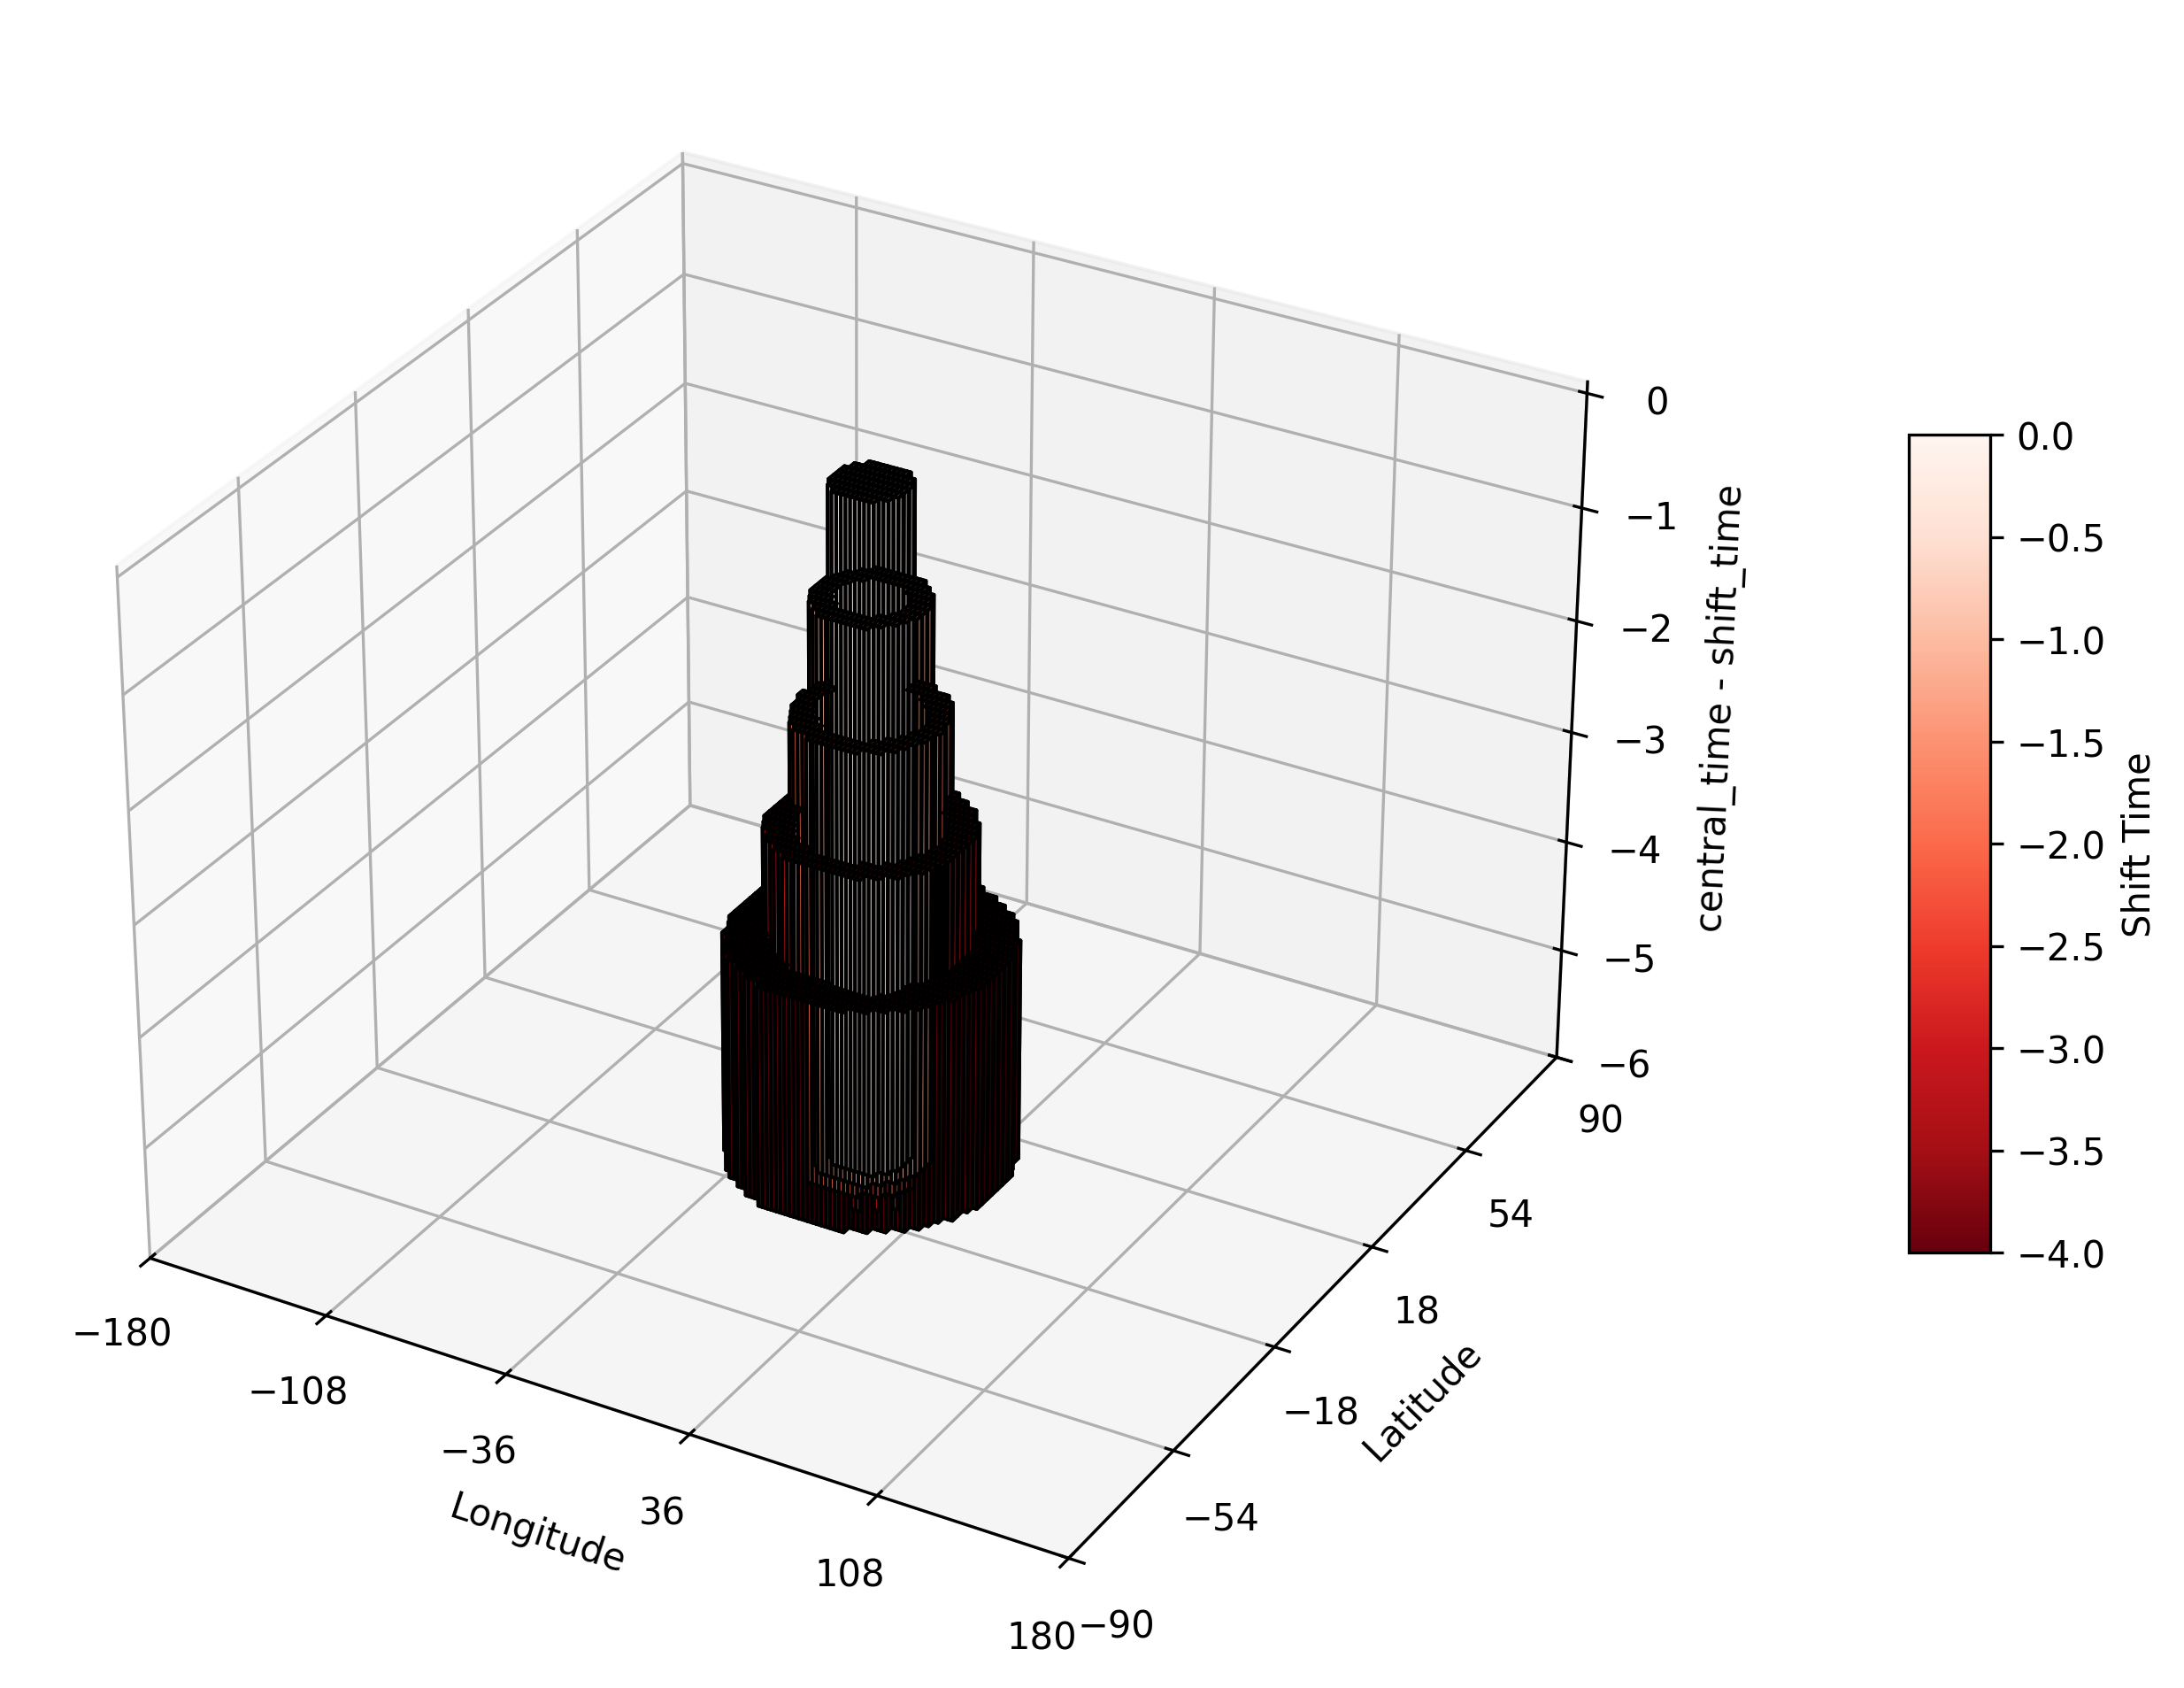

In [54]:
from ponds import PONDS, ELLIPSIS, Gauss

# initalize the PONDS object
pd = PONDS(
    lat_size=101,
    lon_size=201,
    time_size=100,
)

# Create a mask with an ellipsis shape
cluster = ELLIPSIS(
    center_lat=0,
    center_lon=0,
    ecc_lat=25,
    ecc_lon=50,
)
cluster_mask = cluster.make_shape(
    lats=pd.lats,
    lons=pd.lons
)

corr = Gauss(
    center_lat=0,       # latitude of the gaussian peak
    center_lon=0,       # longitude of the gaussian peak
    sigma_lat=10,       # gauss standard deviation in latitude
    sigma_lon=20,        # gauss standard deviation in longitude
    max_offset=5
)

shift_times = corr.make_time_offsets(
    cluster_mask,
)

# Use an interactive backend inside Jupyter
%matplotlib inline

fig, ax = barplot_3D(
    cluster_mask,
    pd,
    shift_times,
    alpha=1,
    cmap="Reds_r",
    )
